# 06A FORCE raw RF class conditional transport interventions TIE SAFE

> Saved outputs are from an earlier local run. Portable path edits have **not** been re-executed. See the repository README for setup and scientific limitations.


In [1]:
import sys, subprocess, importlib.util
required={"pandas":"pandas","numpy":"numpy","matplotlib":"matplotlib","sklearn":"scikit-learn","scipy":"scipy","joblib":"joblib","pyarrow":"pyarrow"}
for module,package in required.items():
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable,"-m","pip","install","-q",package])
print("Dependencies are available.")

Dependencies are available.


In [2]:
from pathlib import Path
import gc, hashlib, json, math, platform, time, warnings
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy, sklearn
from scipy.stats import spearmanr, wilcoxon
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns",300)
pd.set_option("display.max_rows",300)
pd.set_option("display.max_colwidth",300)
EPS=1e-12
ARGMAX_TIE_TOL=1e-12
RANDOM_STATE=142
np.random.seed(RANDOM_STATE)

In [3]:
RUN_MODE="full"  # "pilot" or "full"
ALL_FOLDS=[1,2,3,4,5]
DOSES=[0.25,0.50,0.75,1.00]
RAW8_FEATURES=["GR","NPHI","RHOB","DTC","RDEP","CALI","PEF","SP"]
PILOT_FOLDS=[1]
PILOT_SOURCE="Shale"
PILOT_TARGET="Limestone"
ACTIVE_FOLDS=PILOT_FOLDS if RUN_MODE=="pilot" else ALL_FOLDS
SAVE_ROW_LEVEL_RESULTS=(RUN_MODE=="pilot")
SKIP_COMPLETED_CONDITIONS=True
PREDICTION_BATCH_SIZE=150_000
BOOTSTRAP_REPLICATES=2000 if RUN_MODE=="pilot" else 1000
MIN_WELLS_FOR_WILCOXON=5
BH_ALPHA=0.05
MAX_TOP_PLOTS=20

# Portable paths: override them with environment variables if upstream artifacts
# live outside this repository. See README -> Reproduction & paths.
import os

def _find_stratashift_root():
    start = Path(os.environ.get("STRATASHIFT_REPO_ROOT", Path.cwd())).expanduser().resolve()
    for candidate in (start, *start.parents):
        if (candidate / "notebooks" / "interventions").is_dir() and (candidate / "README.md").is_file():
            return candidate
    raise FileNotFoundError(
        "StrataShift root not found. Launch Jupyter inside the repository "
        "or set STRATASHIFT_REPO_ROOT."
    )

REPO_ROOT = _find_stratashift_root()
TRAIN_PATH = Path(os.environ.get(
    "STRATASHIFT_TRAIN_CSV", str(REPO_ROOT / "data" / "raw" / "train.csv")
)).expanduser().resolve()
PROJECT = Path(os.environ.get(
    "STRATASHIFT_ARTIFACT_ROOT", str(REPO_ROOT / "artifacts")
)).expanduser().resolve()
FOLD_PATH=PROJECT/"01_clean_splits_support"/"10_grouped_5fold_well_assignment.csv"
D04=PROJECT/"04C_shared_class_conditional_transport_bank"/"full"
BANK_DIR=D04/"transport_bank"
MANIFEST04=D04/"06_transport_bank_manifest.csv"
GATE04=D04/"07_transport_bank_gate.json"
CONFIG04=D04/"08_run_configuration.json"
D05A=PROJECT/"05A_raw_log_feature_contract"/"full"
GATE05A=D05A/"13_raw_feature_contract_gate.json"
CONTRACT05A=D05A/"10_primary_raw_feature_contract.json"
D05B=PROJECT/"05B_raw_log_RF_grouped_well_CV"/"full"
MODEL_DIR=D05B/"models"
GATE05B=D05B/"17_stage_gate.json"
CONFIG05B=D05B/"18_run_configuration.json"
D05C=PROJECT/"05C_raw_RF_strict_nested_temperature_calibration"/"full"
FILE12=D05C/"12_calibrated_OOF_predictions_raw8.parquet"
TEMP_MAP_PATH=D05C/"11_temperature_map.json"
GATE05C=D05C/"13_stage_gate.json"
CONFIG05C=D05C/"14_run_configuration.json"
OUT=PROJECT/"06A_raw_RF_class_conditional_transport_interventions"/RUN_MODE
COND_DIR=OUT/"condition_outputs"
ROW_DIR=OUT/"row_level_results"
WELL_DIR=OUT/"per_well_results"
TRANS_DIR=OUT/"transition_results"
PLOT_DIR=OUT/"plots"
for d in [OUT,COND_DIR,ROW_DIR,WELL_DIR,TRANS_DIR,PLOT_DIR]: d.mkdir(parents=True,exist_ok=True)
SENTINELS={"SP":[-999.0]}
POSITIVE_ONLY={"RDEP"}
required=[TRAIN_PATH,FOLD_PATH,MANIFEST04,GATE04,CONFIG04,GATE05A,CONTRACT05A,GATE05B,CONFIG05B,FILE12,TEMP_MAP_PATH,GATE05C,CONFIG05C]
missing=[str(p) for p in required if not p.exists()]
if missing: raise FileNotFoundError("Missing inputs:\n"+"\n".join(missing))
print("RUN_MODE:",RUN_MODE,"| folds:",ACTIVE_FOLDS,"| row-level:",SAVE_ROW_LEVEL_RESULTS)
print("Output:",OUT)

RUN_MODE: full | folds: [1, 2, 3, 4, 5] | row-level: False
Output: <ARTIFACT_ROOT>/06A_raw_RF_class_conditional_transport_interventions/full


In [4]:
def sha256_file(path,chunk=1024*1024):
    h=hashlib.sha256()
    with open(path,"rb") as f:
        while True:
            b=f.read(chunk)
            if not b: break
            h.update(b)
    return h.hexdigest()

def json_safe(x):
    if isinstance(x,dict): return {str(k):json_safe(v) for k,v in x.items()}
    if isinstance(x,(list,tuple)): return [json_safe(v) for v in x]
    if isinstance(x,(np.integer,)): return int(x)
    if isinstance(x,(np.floating,)): return float(x)
    if isinstance(x,(np.bool_,)): return bool(x)
    if x is None: return None
    try:
        if pd.isna(x): return None
    except Exception: pass
    return x

def dose_col(alpha): return f"value_alpha_{float(alpha):.2f}".replace(".","_")

def stable_seed(*parts):
    return int(hashlib.sha256("||".join(map(str,parts)).encode()).hexdigest()[:8],16)

with open(GATE04,encoding="utf-8") as f: gate04=json.load(f)
with open(CONFIG04,encoding="utf-8") as f: config04=json.load(f)
with open(GATE05A,encoding="utf-8") as f: gate05a=json.load(f)
with open(CONTRACT05A,encoding="utf-8") as f: contract05a=json.load(f)
with open(GATE05B,encoding="utf-8") as f: gate05b=json.load(f)
with open(CONFIG05B,encoding="utf-8") as f: config05b=json.load(f)
with open(GATE05C,encoding="utf-8") as f: gate05c=json.load(f)
with open(CONFIG05C,encoding="utf-8") as f: config05c=json.load(f)
with open(TEMP_MAP_PATH,encoding="utf-8") as f: temperature_map=json.load(f)
upstream={
 "04C_passed":bool(gate04.get("overall_transport_bank_passed",False)),
 "04C_outer_train_mapping":bool(gate04.get("mapping_built_from_outer_training_only",False)),
 "05A_passed":bool(gate05a.get("overall_raw_feature_contract_passed",False)),
 "feature_order_exact":contract05a.get("input_features",[])==RAW8_FEATURES,
 "05B_full_passed":bool(gate05b.get("overall_raw_RF_grouped_CV_passed",False)),
 "05C_full_passed":bool(gate05c.get("overall_strict_nested_temperature_calibration_passed",False)),
 "05C_nested":bool(gate05c.get("strict_nested_grouped_calibration_used",False)),
 "file12_exists":FILE12.exists(),
 "all_raw8_temperatures":set(temperature_map.get("raw8",{}))=={str(f) for f in ALL_FOLDS},
 "official_test_unused":bool(gate04.get("official_test_unused",False) and gate05b.get("official_test_unused",False) and gate05c.get("official_test_unused",False)),
}
print(json.dumps(upstream,indent=2))
if not all(upstream.values()): raise RuntimeError("Upstream audit failed.")

{
  "04C_passed": true,
  "04C_outer_train_mapping": true,
  "05A_passed": true,
  "feature_order_exact": true,
  "05B_full_passed": true,
  "05C_full_passed": true,
  "05C_nested": true,
  "file12_exists": true,
  "all_raw8_temperatures": true,
  "official_test_unused": true
}


In [5]:
def detect_csv(path):
    for enc in ["utf-8","latin1","cp1252"]:
        try:
            text=Path(path).read_text(encoding=enc)[:5000]
            sep="," if "," in text else (";" if ";" in text else "\t")
            return sep,enc
        except UnicodeDecodeError: pass
    return ",","utf-8"
sep,enc=detect_csv(TRAIN_PATH)
train=pd.read_csv(TRAIN_PATH,sep=sep,encoding=enc,low_memory=False)
train["ORIGINAL_ROW_ID"]=np.arange(len(train),dtype=np.int64)
fold_raw=pd.read_csv(FOLD_PATH)
well_col=[c for c in fold_raw.columns if c.upper()=="WELL"][0]
fold_col=[c for c in fold_raw.columns if "FOLD" in c.upper() and "SCORE" not in c.upper()][0]
fold_map=(fold_raw[[well_col,fold_col]].rename(columns={well_col:"WELL",fold_col:"GROUP_FOLD"}).drop_duplicates("WELL"))
fold_map["GROUP_FOLD"]=pd.to_numeric(fold_map.GROUP_FOLD,errors="raise").astype(int)
train["GROUP_FOLD"]=train.WELL.map(dict(zip(fold_map.WELL,fold_map.GROUP_FOLD)))
if train.GROUP_FOLD.isna().any(): raise RuntimeError("Missing fold assignment.")
train["GROUP_FOLD"]=train.GROUP_FOLD.astype(int)
TARGET="FORCE_2020_LITHOFACIES_LITHOLOGY"
CLASSES=np.array([30000,65000,65030,70000,70032,74000,80000,86000,88000,90000,93000,99000],dtype=np.int64)
NAMES={30000:"Sandstone",65000:"Shale",65030:"Sandstone/Shale",70000:"Limestone",70032:"Chalk",74000:"Dolomite",80000:"Marl",86000:"Anhydrite",88000:"Halite",90000:"Coal",93000:"Basement",99000:"Tuff"}
CLASS_TO_INDEX={int(c):i for i,c in enumerate(CLASSES)}
train["LITHOLOGY_CODE"]=pd.to_numeric(train[TARGET],errors="raise").astype(np.int64)

def clean_series(df,feature):
    s=pd.to_numeric(df[feature],errors="coerce").astype(float)
    for sentinel in SENTINELS.get(feature,[]):
        s.loc[np.isclose(s.to_numpy(float),sentinel,rtol=0,atol=1e-12,equal_nan=False)]=np.nan
    arr=s.to_numpy(float); s.loc[~np.isfinite(arr)]=np.nan
    if feature in POSITIVE_ONLY: s.loc[s.notna() & (s<=0)]=np.nan
    return s
clean=pd.DataFrame(index=train.index)
for feature in RAW8_FEATURES: clean[feature]=clean_series(train,feature).astype(np.float32)
cleaning_summary=pd.DataFrame({"feature":RAW8_FEATURES,"missing_rate":[clean[f].isna().mean() for f in RAW8_FEATURES],"observed_rows":[clean[f].notna().sum() for f in RAW8_FEATURES]})
print("Rows:",len(train),"Wells:",train.WELL.nunique())
display(cleaning_summary)

Rows: 1170511 Wells: 98


,feature,missing_rate,observed_rows
0,GR,0.000000,1170511
1,NPHI,0.346090,765409
2,RHOB,0.137777,1009242
3,DTC,0.069084,1089648
4,RDEP,0.009410,1159496
5,CALI,0.075076,1082634
6,PEF,0.426155,671692
7,SP,0.261993,863845


In [6]:
RAW_PROB_COLS=[f"prob_{c}" for c in CLASSES]
CAL_PROB_COLS=[f"cal_prob_{c}" for c in CLASSES]
OOF_COLS=["ORIGINAL_ROW_ID","WELL","outer_fold","true_code","predicted_code","calibrated_predicted_code","temperature"]+RAW_PROB_COLS+CAL_PROB_COLS
oof=pd.read_parquet(FILE12,columns=OOF_COLS).sort_values("ORIGINAL_ROW_ID").reset_index(drop=True)
Praw=oof[RAW_PROB_COLS].to_numpy(float); Pcal=oof[CAL_PROB_COLS].to_numpy(float)
oof_audit={
 "rows_exact":len(oof)==len(train),
 "row_ids_unique":not oof.ORIGINAL_ROW_ID.duplicated().any(),
 "row_id_set_exact":set(oof.ORIGINAL_ROW_ID)==set(train.ORIGINAL_ROW_ID),
 "five_folds":sorted(oof.outer_fold.unique().tolist())==ALL_FOLDS,
 "raw_finite":bool(np.isfinite(Praw).all()),
 "cal_finite":bool(np.isfinite(Pcal).all()),
 "raw_sum_one":bool(np.allclose(Praw.sum(1),1,rtol=1e-6,atol=1e-6)),
 "cal_sum_one":bool(np.allclose(Pcal.sum(1),1,rtol=1e-6,atol=1e-6)),
 "argmax_unchanged":bool((oof.predicted_code==oof.calibrated_predicted_code).all()),
}
print(json.dumps(oof_audit,indent=2))
if not all(oof_audit.values()): raise RuntimeError("File-12 audit failed.")
oof_idx=oof.set_index("ORIGINAL_ROW_ID",drop=False)
del Praw,Pcal; gc.collect()

{
  "rows_exact": true,
  "row_ids_unique": true,
  "row_id_set_exact": true,
  "five_folds": true,
  "raw_finite": true,
  "cal_finite": true,
  "raw_sum_one": true,
  "cal_sum_one": true,
  "argmax_unchanged": true
}


33

In [7]:
manifest=pd.read_csv(MANIFEST04)
needed={"condition_id","outer_fold","feature","source_name","target_name","bank_sha256"}
if needed-set(manifest.columns): raise KeyError("Manifest columns missing.")
manifest["outer_fold"]=pd.to_numeric(manifest.outer_fold,errors="raise").astype(int)
manifest["resolved_bank_path"]=manifest.condition_id.map(lambda x:str(BANK_DIR/f"{x}.parquet"))
if RUN_MODE=="pilot":
    selected=manifest.loc[(manifest.outer_fold.isin(ACTIVE_FOLDS))&(manifest.source_name==PILOT_SOURCE)&(manifest.target_name==PILOT_TARGET)&(manifest.feature.isin(RAW8_FEATURES))].copy()
else:
    selected=manifest.loc[manifest.outer_fold.isin(ACTIVE_FOLDS)].copy()
selected=selected.sort_values(["outer_fold","feature","source_name","target_name"]).reset_index(drop=True)
selected["bank_exists"]=selected.resolved_bank_path.map(lambda x:Path(x).exists())
if not selected.bank_exists.all(): raise FileNotFoundError("Selected bank file missing.")
if RUN_MODE=="pilot" and len(selected)!=8: raise RuntimeError(f"Pilot expected 8 conditions, found {len(selected)}")
print("Selected conditions:",len(selected))
display(selected[["condition_id","outer_fold","feature","source_name","target_name"]])

Selected conditions: 319


,condition_id,outer_fold,feature,source_name,target_name
0,fold_1__feature_CALI__source_74000_Dolomite__target_70000_Limestone,1,CALI,Dolomite,Limestone
1,fold_1__feature_CALI__source_70000_Limestone__target_74000_Dolomite,1,CALI,Limestone,Dolomite
2,fold_1__feature_CALI__source_70000_Limestone__target_65000_Shale,1,CALI,Limestone,Shale
3,fold_1__feature_CALI__source_30000_Sandstone__target_65000_Shale,1,CALI,Sandstone,Shale
4,fold_1__feature_CALI__source_65030_Sandstone_Shale__target_65000_Shale,1,CALI,Sandstone/Shale,Shale
...,...,...,...,...,...
314,fold_5__feature_SP__source_30000_Sandstone__target_65000_Shale,5,SP,Sandstone,Shale
315,fold_5__feature_SP__source_65030_Sandstone_Shale__target_65000_Shale,5,SP,Sandstone/Shale,Shale
316,fold_5__feature_SP__source_65000_Shale__target_70000_Limestone,5,SP,Shale,Limestone
317,fold_5__feature_SP__source_65000_Shale__target_30000_Sandstone,5,SP,Shale,Sandstone


In [8]:
def align_probabilities(local,local_classes):
    out=np.zeros((len(local),len(CLASSES)),dtype=np.float64)
    for j,c in enumerate(local_classes): out[:,CLASS_TO_INDEX[int(c)]]=local[:,j]
    return out/out.sum(1,keepdims=True)

def predict_batches(model,X,batch=PREDICTION_BATCH_SIZE):
    parts=[]
    for start in range(0,len(X),batch):
        local=model.predict_proba(X[start:start+batch])
        parts.append(align_probabilities(local,model.classes_))
    return np.vstack(parts)

def apply_temperature(P,T):
    Z=np.log(np.clip(np.asarray(P,float),EPS,1))/float(T)
    Z-=Z.max(1,keepdims=True)
    E=np.exp(Z)
    return E/E.sum(1,keepdims=True)

def temperature_argmax_audit(P_raw,P_cal,tolerance=ARGMAX_TIE_TOL):
    P_raw=np.asarray(P_raw,dtype=np.float64)
    P_cal=np.asarray(P_cal,dtype=np.float64)

    raw_index=np.argmax(P_raw,axis=1)
    calibrated_index=np.argmax(P_cal,axis=1)
    mismatch=raw_index!=calibrated_index

    top_two=np.partition(P_raw,-2,axis=1)[:,-2:]
    raw_top2_margin=top_two[:,1]-top_two[:,0]

    non_tie_mismatch=(
        mismatch
        & (raw_top2_margin>tolerance)
    )

    return {
      "probabilities_valid":bool(
          np.isfinite(P_raw).all()
          and np.isfinite(P_cal).all()
          and np.allclose(P_raw.sum(1),1,rtol=1e-6,atol=1e-6)
          and np.allclose(P_cal.sum(1),1,rtol=1e-6,atol=1e-6)
      ),
      "argmax_mismatch_rows":int(mismatch.sum()),
      "argmax_mismatch_rate":float(mismatch.mean()),
      "non_tie_argmax_mismatch_rows":int(non_tie_mismatch.sum()),
      "all_argmax_mismatches_are_near_ties":bool(
          not non_tie_mismatch.any()
      ),
      "maximum_raw_top2_margin_among_mismatches":float(
          raw_top2_margin[mismatch].max()
      ) if mismatch.any() else 0.0,
      "tolerance":float(tolerance),
    }

def bootstrap_ci(values,reps,seed):
    v=np.asarray(values,float); v=v[np.isfinite(v)]
    if len(v)==0: return np.nan,np.nan,np.nan
    if len(v)==1: return float(v[0]),float(v[0]),float(v[0])
    rng=np.random.default_rng(seed)
    means=v[rng.integers(0,len(v),size=(reps,len(v)))].mean(1)
    return float(v.mean()),float(np.quantile(means,.025)),float(np.quantile(means,.975))

def safe_wilcoxon(values):
    v=np.asarray(values,float); v=v[np.isfinite(v)]
    if len(v)<MIN_WELLS_FOR_WILCOXON: return np.nan
    if np.allclose(v,0,rtol=0,atol=1e-14): return 1.0
    try: return float(wilcoxon(v,zero_method="wilcox",alternative="two-sided",method="auto").pvalue)
    except ValueError: return 1.0

def bh(p):
    p=np.asarray(p,float); q=np.full(len(p),np.nan); idx=np.where(np.isfinite(p))[0]
    if len(idx)==0:return q
    order=np.argsort(p[idx]); ranked=p[idx][order]; m=len(ranked)
    adj=np.minimum.accumulate((ranked*m/np.arange(1,m+1))[::-1])[::-1]
    q[idx[order]]=np.clip(adj,0,1)
    return q

In [9]:
fold_replay=[]
fold_cache={}
for fold in ACTIVE_FOLDS:
    prefix=f"raw8__outer_fold_{fold}"
    model_path=MODEL_DIR/f"{prefix}__RF.joblib"
    imputer_path=MODEL_DIR/f"{prefix}__median_imputer.joblib"
    metadata_path=MODEL_DIR/f"{prefix}__metadata.json"
    for p in [model_path,imputer_path,metadata_path]:
        if not p.exists(): raise FileNotFoundError(str(p))
    model=joblib.load(model_path); imputer=joblib.load(imputer_path)
    with open(metadata_path,encoding="utf-8") as f: meta=json.load(f)
    if meta.get("feature_list")!=RAW8_FEATURES: raise RuntimeError("Feature order mismatch.")
    mask=(train.GROUP_FOLD==fold).to_numpy(); ids=train.loc[mask,"ORIGINAL_ROW_ID"].to_numpy(np.int64)
    Xraw=clean.loc[mask,RAW8_FEATURES].to_numpy(np.float32)
    X=imputer.transform(Xraw).astype(np.float32,copy=False)
    replay_raw=predict_batches(model,X)
    T=float(temperature_map["raw8"][str(fold)])
    replay_cal=apply_temperature(replay_raw,T)
    stored=oof_idx.loc[ids]
    stored_raw=stored[RAW_PROB_COLS].to_numpy(float); stored_cal=stored[CAL_PROB_COLS].to_numpy(float)
    record={
      "outer_fold":fold,"rows":len(ids),"wells":train.loc[mask,"WELL"].nunique(),"temperature":T,
      "model_features_correct":int(model.n_features_in_)==8,
      "imputer_features_correct":int(imputer.n_features_in_)==8,
      "raw_replay_matches_file12":bool(np.allclose(replay_raw,stored_raw,rtol=1e-6,atol=1e-6)),
      "calibrated_replay_matches_file12":bool(np.allclose(replay_cal,stored_cal,rtol=1e-6,atol=1e-6)),
      "max_abs_raw_difference":float(np.max(np.abs(replay_raw-stored_raw))),
      "max_abs_cal_difference":float(np.max(np.abs(replay_cal-stored_cal))),
      "predicted_labels_match":bool(np.array_equal(CLASSES[np.argmax(replay_raw,1)],stored.predicted_code.to_numpy(np.int64))),
      "no_refit":True,"official_test_unused":True,
    }
    record["fold_replay_passed"]=bool(all(v for k,v in record.items() if k not in ["outer_fold","rows","wells","temperature","max_abs_raw_difference","max_abs_cal_difference","fold_replay_passed"]))
    if not record["fold_replay_passed"]: raise RuntimeError(f"Replay failed fold {fold}")
    fold_replay.append(record)
    fold_cache[fold]={
        "model_path":model_path,
        "imputer_path":imputer_path,
        "temperature":T,
    }
    print(json.dumps(record,indent=2))
    del model,imputer,Xraw,X,replay_raw,replay_cal,stored,stored_raw,stored_cal
    gc.collect()
fold_replay_df=pd.DataFrame(fold_replay)

{
  "outer_fold": 1,
  "rows": 232674,
  "wells": 20,
  "temperature": 1.0344845096586226,
  "model_features_correct": true,
  "imputer_features_correct": true,
  "raw_replay_matches_file12": true,
  "calibrated_replay_matches_file12": true,
  "max_abs_raw_difference": 2.980201618818512e-08,
  "max_abs_cal_difference": 4.974944012303695e-08,
  "predicted_labels_match": true,
  "no_refit": true,
  "official_test_unused": true,
  "fold_replay_passed": true
}
{
  "outer_fold": 2,
  "rows": 236205,
  "wells": 20,
  "temperature": 0.9930241250425766,
  "model_features_correct": true,
  "imputer_features_correct": true,
  "raw_replay_matches_file12": true,
  "calibrated_replay_matches_file12": true,
  "max_abs_raw_difference": 2.9801978440602284e-08,
  "max_abs_cal_difference": 4.90128091445996e-08,
  "predicted_labels_match": true,
  "no_refit": true,
  "official_test_unused": true,
  "fold_replay_passed": true
}
{
  "outer_fold": 3,
  "rows": 230578,
  "wells": 21,
  "temperature": 1.02055

In [10]:
def build_row_effects(bank,control,Pi_raw,Pi_cal,alpha,source_code,target_code):
    si=CLASS_TO_INDEX[source_code]; ti=CLASS_TO_INDEX[target_code]
    Pc_raw=control[RAW_PROB_COLS].to_numpy(float); Pc_cal=control[CAL_PROB_COLS].to_numpy(float)
    pcrs=Pc_raw[:,si]; pirs=Pi_raw[:,si]; pccs=Pc_cal[:,si]; pics=Pi_cal[:,si]
    pcrt=Pc_raw[:,ti]; pirt=Pi_raw[:,ti]; pcct=Pc_cal[:,ti]; pict=Pi_cal[:,ti]
    pred_c=CLASSES[np.argmax(Pc_raw,1)]
    pred_i=CLASSES[np.argmax(Pi_raw,1)]
    pred_i_cal=CLASSES[np.argmax(Pi_cal,1)]

    top_two=np.partition(Pi_raw,-2,axis=1)[:,-2:]
    raw_top2_margin=top_two[:,1]-top_two[:,0]

    calibrated_argmax_differs=pred_i!=pred_i_cal
    non_tie_difference=(
        calibrated_argmax_differs
        & (raw_top2_margin>ARGMAX_TIE_TOL)
    )

    if non_tie_difference.any():
        raise RuntimeError(
            "Calibration changed intervention argmax outside a numerical tie."
        )

    correct_c=pred_c==source_code
    correct_i=pred_i==source_code
    return pd.DataFrame({
      "ORIGINAL_ROW_ID":bank.ORIGINAL_ROW_ID.to_numpy(np.int64),"WELL":bank.WELL.to_numpy(),"DEPTH_MD":bank.DEPTH_MD.to_numpy(float),
      "outer_fold":bank.outer_fold.to_numpy(np.int64),"feature":bank.feature.to_numpy(),"source_code":source_code,"source_name":bank.source_name.to_numpy(),
      "target_code":target_code,"target_name":bank.target_name.to_numpy(),"alpha":float(alpha),"transport_space":bank.transport_space.to_numpy(),
      "original_value":bank.original_value.to_numpy(float),"intervened_value":bank[dose_col(alpha)].to_numpy(float),
      "target_quantile_value":bank.target_quantile_value.to_numpy(float),"source_percentile":bank.source_percentile.to_numpy(float),
      "normalized_full_transport_shift":bank.normalized_full_transport_shift.to_numpy(float),
      "control_predicted_code":pred_c,"intervened_predicted_code":pred_i,
      "calibrated_intervened_argmax_code":pred_i_cal,
      "calibrated_argmax_differs_from_raw":calibrated_argmax_differs,
      "raw_top2_probability_margin":raw_top2_margin,
      "calibration_argmax_difference_is_near_tie":(
          (~calibrated_argmax_differs)
          | (raw_top2_margin<=ARGMAX_TIE_TOL)
      ),
      "control_correct":correct_c,"intervened_correct":correct_i,
      "accuracy_change":correct_i.astype(np.int8)-correct_c.astype(np.int8),"any_flip":pred_i!=pred_c,
      "targeted_source_to_target_flip":(pred_c==source_code)&(pred_i==target_code),
      "target_acquired_from_non_target":(pred_c!=target_code)&(pred_i==target_code),
      "correct_to_incorrect":correct_c&(~correct_i),"incorrect_to_correct":(~correct_c)&correct_i,
      "raw_delta_source_probability":pirs-pcrs,"raw_delta_target_probability":pirt-pcrt,
      "raw_control_log_loss":-np.log(np.clip(pcrs,EPS,1)),"raw_intervened_log_loss":-np.log(np.clip(pirs,EPS,1)),
      "raw_delta_log_loss":-np.log(np.clip(pirs,EPS,1))+np.log(np.clip(pcrs,EPS,1)),
      "calibrated_delta_source_probability":pics-pccs,"calibrated_delta_target_probability":pict-pcct,
      "calibrated_control_log_loss":-np.log(np.clip(pccs,EPS,1)),"calibrated_intervened_log_loss":-np.log(np.clip(pics,EPS,1)),
      "calibrated_delta_log_loss":-np.log(np.clip(pics,EPS,1))+np.log(np.clip(pccs,EPS,1)),
    })

def per_well_summary(rows):
    return rows.groupby(["WELL","outer_fold","feature","source_code","source_name","target_code","target_name","alpha"],as_index=False).agg(
      rows=("ORIGINAL_ROW_ID","size"),baseline_accuracy=("control_correct","mean"),intervention_accuracy=("intervened_correct","mean"),
      accuracy_change=("accuracy_change","mean"),mean_raw_delta_log_loss=("raw_delta_log_loss","mean"),
      mean_calibrated_delta_log_loss=("calibrated_delta_log_loss","mean"),mean_raw_delta_source_probability=("raw_delta_source_probability","mean"),
      mean_calibrated_delta_source_probability=("calibrated_delta_source_probability","mean"),mean_raw_delta_target_probability=("raw_delta_target_probability","mean"),
      mean_calibrated_delta_target_probability=("calibrated_delta_target_probability","mean"),any_flip_rate=("any_flip","mean"),
      targeted_flip_rate=("targeted_source_to_target_flip","mean"),target_acquisition_rate=("target_acquired_from_non_target","mean"),
      correct_to_incorrect_rate=("correct_to_incorrect","mean"),incorrect_to_correct_rate=("incorrect_to_correct","mean"),
      mean_normalized_transport_shift=("normalized_full_transport_shift","mean"))

def dose_summary(rows,wells,condition_id,alpha):
    raw_mean,raw_lo,raw_hi=bootstrap_ci(wells.mean_raw_delta_log_loss,BOOTSTRAP_REPLICATES,stable_seed(condition_id,alpha,"raw"))
    cal_mean,cal_lo,cal_hi=bootstrap_ci(wells.mean_calibrated_delta_log_loss,BOOTSTRAP_REPLICATES,stable_seed(condition_id,alpha,"cal"))
    base_correct=int(rows.control_correct.sum()); base_wrong=int((~rows.control_correct).sum())
    c2i=float(rows.loc[rows.control_correct,"correct_to_incorrect"].mean()) if base_correct else np.nan
    i2c=float(rows.loc[~rows.control_correct,"incorrect_to_correct"].mean()) if base_wrong else np.nan
    return {
      "condition_id":condition_id,"outer_fold":int(rows.outer_fold.iloc[0]),"feature":rows.feature.iloc[0],"source_code":int(rows.source_code.iloc[0]),
      "source_name":rows.source_name.iloc[0],"target_code":int(rows.target_code.iloc[0]),"target_name":rows.target_name.iloc[0],"alpha":float(alpha),
      "rows":len(rows),"wells":rows.WELL.nunique(),"pooled_baseline_accuracy":float(rows.control_correct.mean()),
      "pooled_intervention_accuracy":float(rows.intervened_correct.mean()),"pooled_accuracy_change":float(rows.accuracy_change.mean()),
      "well_balanced_accuracy_change":float(wells.accuracy_change.mean()),"pooled_mean_raw_delta_log_loss":float(rows.raw_delta_log_loss.mean()),
      "well_balanced_mean_raw_delta_log_loss":raw_mean,"raw_CI_lower":raw_lo,"raw_CI_upper":raw_hi,"raw_wilcoxon_pvalue":safe_wilcoxon(wells.mean_raw_delta_log_loss),
      "pooled_mean_calibrated_delta_log_loss":float(rows.calibrated_delta_log_loss.mean()),"well_balanced_mean_calibrated_delta_log_loss":cal_mean,
      "calibrated_CI_lower":cal_lo,"calibrated_CI_upper":cal_hi,"calibrated_wilcoxon_pvalue":safe_wilcoxon(wells.mean_calibrated_delta_log_loss),
      "mean_raw_delta_source_probability":float(rows.raw_delta_source_probability.mean()),"mean_calibrated_delta_source_probability":float(rows.calibrated_delta_source_probability.mean()),
      "mean_raw_delta_target_probability":float(rows.raw_delta_target_probability.mean()),"mean_calibrated_delta_target_probability":float(rows.calibrated_delta_target_probability.mean()),
      "pooled_any_flip_rate":float(rows.any_flip.mean()),"well_balanced_any_flip_rate":float(wells.any_flip_rate.mean()),
      "pooled_targeted_flip_rate":float(rows.targeted_source_to_target_flip.mean()),"well_balanced_targeted_flip_rate":float(wells.targeted_flip_rate.mean()),
      "correct_to_incorrect_rate_given_control_correct":c2i,"incorrect_to_correct_rate_given_control_incorrect":i2c,
      "fraction_wells_positive_calibrated_delta_log_loss":float((wells.mean_calibrated_delta_log_loss>0).mean()),
      "mean_normalized_transport_shift":float(rows.normalized_full_transport_shift.mean()),"bootstrap_replicates":BOOTSTRAP_REPLICATES,
    }

In [11]:
summary_records=[]; well_frames=[]; transition_frames=[]; execution_records=[]; gate_records=[]
start_all=time.time()
for fold in ACTIVE_FOLDS:
    runtime=fold_cache[fold]
    model=joblib.load(runtime["model_path"])
    imputer=joblib.load(runtime["imputer_path"])
    T=runtime["temperature"]
    fold_conditions=selected.loc[selected.outer_fold==fold]
    for ordinal,(_,cond) in enumerate(fold_conditions.iterrows(),1):
        t0=time.time(); condition_id=str(cond.condition_id); feature=str(cond.feature); bank_path=Path(cond.resolved_bank_path)
        summary_path=COND_DIR/f"{condition_id}__intervention_summary.json"
        well_path=WELL_DIR/f"{condition_id}__per_well.parquet"
        trans_path=TRANS_DIR/f"{condition_id}__transitions.parquet"
        row_path=ROW_DIR/f"{condition_id}__row_effects.parquet"
        cache=[summary_path,well_path,trans_path]+([row_path] if SAVE_ROW_LEVEL_RESULTS else [])
        if SKIP_COMPLETED_CONDITIONS and all(p.exists() for p in cache):
            with open(summary_path,encoding="utf-8") as f: payload=json.load(f)
            if not payload.get("condition_gate_passed",False): raise RuntimeError("Cached gate failed")
            summary_records.extend(payload["dose_summaries"]); well_frames.append(pd.read_parquet(well_path)); transition_frames.append(pd.read_parquet(trans_path)); gate_records.append(payload["condition_gate"])
            execution_records.append({"condition_id":condition_id,"outer_fold":fold,"feature":feature,"source_name":cond.source_name,"target_name":cond.target_name,"status":"cache","seconds":0.0})
            print("[cache]",condition_id); continue
        print(f"[fold {fold} {ordinal}/{len(fold_conditions)}] {condition_id}")
        observed_hash=sha256_file(bank_path)
        if observed_hash!=str(cond.bank_sha256): raise RuntimeError(f"Bank hash mismatch {condition_id}")
        bank=pd.read_parquet(bank_path).sort_values("ORIGINAL_ROW_ID").reset_index(drop=True)
        needed={"ORIGINAL_ROW_ID","WELL","DEPTH_MD","LITHOLOGY_CODE","outer_fold","feature","source_code","source_name","target_code","target_name","transport_space","original_value","source_percentile","target_quantile_value","normalized_full_transport_shift"}|{dose_col(a) for a in DOSES}
        if needed-set(bank.columns): raise KeyError(f"Bank columns missing: {needed-set(bank.columns)}")
        ids=bank.ORIGINAL_ROW_ID.to_numpy(np.int64); source_code=int(bank.source_code.iloc[0]); target_code=int(bank.target_code.iloc[0]); feature_index=RAW8_FEATURES.index(feature)
        source_rows=train.iloc[ids]; Xbase=clean.iloc[ids][RAW8_FEATURES].to_numpy(np.float32); original=Xbase[:,feature_index].astype(float)
        control=oof_idx.loc[ids]
        dose_matrices=[]; only_feature=[]; dose_finite=[]
        other=[i for i in range(8) if i!=feature_index]
        for alpha in DOSES:
            X=Xbase.copy(); vals=bank[dose_col(alpha)].to_numpy(np.float32); X[:,feature_index]=vals
            dose_finite.append(bool(np.isfinite(vals).all())); only_feature.append(bool(np.allclose(X[:,other],Xbase[:,other],rtol=0,atol=0,equal_nan=True))); dose_matrices.append(X)
        Xstack=np.vstack(dose_matrices); Ximp=imputer.transform(Xstack).astype(np.float32,copy=False)
        Pi_raw_all=predict_batches(model,Ximp); Pi_cal_all=apply_temperature(Pi_raw_all,T)
        n=len(bank); row_parts=[]; well_parts=[]; trans_parts=[]; dose_summaries=[]; prob_checks=[]
        for j,alpha in enumerate(DOSES):
            Pi_raw=Pi_raw_all[j*n:(j+1)*n]; Pi_cal=Pi_cal_all[j*n:(j+1)*n]
            argmax_audit=temperature_argmax_audit(
                Pi_raw,
                Pi_cal,
            )
            argmax_audit["alpha"]=float(alpha)
            prob_checks.append(argmax_audit)
            rows=build_row_effects(bank,control,Pi_raw,Pi_cal,alpha,source_code,target_code); wells=per_well_summary(rows); dose_summaries.append(dose_summary(rows,wells,condition_id,alpha))
            trans=rows.groupby(["outer_fold","feature","source_code","source_name","target_code","target_name","alpha","control_predicted_code","intervened_predicted_code"],as_index=False).agg(rows=("ORIGINAL_ROW_ID","size"),wells=("WELL","nunique"))
            trans["control_predicted_name"]=trans.control_predicted_code.map(NAMES); trans["intervened_predicted_name"]=trans.intervened_predicted_code.map(NAMES)
            row_parts.append(rows); well_parts.append(wells); trans_parts.append(trans)
        rows_all=pd.concat(row_parts,ignore_index=True); wells_all=pd.concat(well_parts,ignore_index=True); trans_all=pd.concat(trans_parts,ignore_index=True)
        gate={
          "condition_id":condition_id,"outer_fold":fold,"feature":feature,"source_code":source_code,"target_code":target_code,
          "bank_hash_matches":True,"bank_row_ids_unique":not bank.ORIGINAL_ROW_ID.duplicated().any(),
          "source_labels_match":bool((source_rows.LITHOLOGY_CODE.to_numpy(np.int64)==source_code).all()),
          "outer_fold_matches":bool((source_rows.GROUP_FOLD.to_numpy(np.int64)==fold).all()),
          "row_ids_match_control":bool(np.array_equal(control.ORIGINAL_ROW_ID.to_numpy(np.int64),ids)),
          "control_labels_match_source":bool((control.true_code.to_numpy(np.int64)==source_code).all()),
          "original_values_match_bank":bool(np.allclose(original,bank.original_value.to_numpy(float),rtol=1e-6,atol=1e-6)),
          "treatment_originally_observed":bool(np.isfinite(original).all()),"only_treatment_feature_changed":bool(all(only_feature)),
          "all_dose_values_finite":bool(all(dose_finite)),
          "all_probability_checks":bool(
              all(
                  check["probabilities_valid"]
                  for check in prob_checks
              )
          ),
          "calibration_argmax_mismatches_only_near_ties":bool(
              all(
                  check["all_argmax_mismatches_are_near_ties"]
                  for check in prob_checks
              )
          ),
          "four_doses":sorted(rows_all.alpha.unique().tolist())==DOSES,
          "rows_per_dose":bool((rows_all.groupby("alpha").size()==len(bank)).all()),"true_label_unchanged":bool((rows_all.source_code==source_code).all()),
          "model_and_imputer_frozen":True,"temperature_frozen":True,"official_test_unused":True,
        }
        gate["condition_gate_passed"]=bool(all(v for k,v in gate.items() if k not in ["condition_id","outer_fold","feature","source_code","target_code","condition_gate_passed"]))
        if not gate["condition_gate_passed"]: raise RuntimeError(f"Condition gate failed {condition_id}")
        wells_all.to_parquet(well_path,index=False); trans_all.to_parquet(trans_path,index=False)
        if SAVE_ROW_LEVEL_RESULTS: rows_all.to_parquet(row_path,index=False)
        payload={"condition_id":condition_id,"dose_summaries":[json_safe(r) for r in dose_summaries],"condition_gate":json_safe(gate),"condition_gate_passed":True,"temperature":T,"bank_sha256":observed_hash,"row_level_saved":SAVE_ROW_LEVEL_RESULTS,"intervention_argmax_audit":[json_safe(r) for r in prob_checks],"seconds":time.time()-t0}
        with open(summary_path,"w",encoding="utf-8") as f: json.dump(payload,f,indent=2,ensure_ascii=False)
        summary_records.extend(dose_summaries); well_frames.append(wells_all); transition_frames.append(trans_all); gate_records.append(gate)
        execution_records.append({"condition_id":condition_id,"outer_fold":fold,"feature":feature,"source_name":bank.source_name.iloc[0],"target_name":bank.target_name.iloc[0],"status":"built","seconds":time.time()-t0})
        print(f"  PASS rows={len(bank):,} wells={bank.WELL.nunique()} seconds={time.time()-t0:.1f}")
        del bank,source_rows,Xbase,control,dose_matrices,Xstack,Ximp,Pi_raw_all,Pi_cal_all,row_parts,well_parts,trans_parts,rows_all,wells_all,trans_all; gc.collect()
    # Only one 800-tree forest remains in memory at a time.
    del model,imputer
    gc.collect()
print("Total seconds:",time.time()-start_all)

[cache] fold_1__feature_CALI__source_74000_Dolomite__target_70000_Limestone
[cache] fold_1__feature_CALI__source_70000_Limestone__target_74000_Dolomite
[cache] fold_1__feature_CALI__source_70000_Limestone__target_65000_Shale
[cache] fold_1__feature_CALI__source_30000_Sandstone__target_65000_Shale
[cache] fold_1__feature_CALI__source_65030_Sandstone_Shale__target_65000_Shale
[cache] fold_1__feature_CALI__source_65000_Shale__target_70000_Limestone
[cache] fold_1__feature_CALI__source_65000_Shale__target_30000_Sandstone
[cache] fold_1__feature_CALI__source_65000_Shale__target_65030_Sandstone_Shale
[cache] fold_1__feature_DTC__source_74000_Dolomite__target_70000_Limestone
[cache] fold_1__feature_DTC__source_70000_Limestone__target_74000_Dolomite
[cache] fold_1__feature_DTC__source_70000_Limestone__target_65000_Shale
[cache] fold_1__feature_DTC__source_30000_Sandstone__target_65000_Shale
[cache] fold_1__feature_DTC__source_65030_Sandstone_Shale__target_65000_Shale
[cache] fold_1__feature_DT

In [12]:
summary=pd.DataFrame(summary_records)
per_well=pd.concat(well_frames,ignore_index=True) if well_frames else pd.DataFrame()
transitions=pd.concat(transition_frames,ignore_index=True) if transition_frames else pd.DataFrame()
execution=pd.DataFrame(execution_records); condition_gates=pd.DataFrame(gate_records)
summary["raw_qvalue"]=np.nan; summary["calibrated_qvalue"]=np.nan
for alpha,g in summary.groupby("alpha"):
    summary.loc[g.index,"raw_qvalue"]=bh(g.raw_wilcoxon_pvalue.to_numpy(float))
    summary.loc[g.index,"calibrated_qvalue"]=bh(g.calibrated_wilcoxon_pvalue.to_numpy(float))
summary["raw_FDR_significant"]=summary.raw_qvalue<=BH_ALPHA
summary["calibrated_FDR_significant"]=summary.calibrated_qvalue<=BH_ALPHA

dose_records=[]
keys=["condition_id","outer_fold","feature","source_code","source_name","target_code","target_name"]
for key,g in summary.groupby(keys):
    g=g.sort_values("alpha"); a=g.alpha.to_numpy(float); ce=g.well_balanced_mean_calibrated_delta_log_loss.to_numpy(float); re=g.well_balanced_mean_raw_delta_log_loss.to_numpy(float)
    cs=spearmanr(a,ce); rs=spearmanr(a,re); rec=dict(zip(keys,key)); rec.update({"calibrated_spearman":float(cs.statistic),"calibrated_spearman_pvalue":float(cs.pvalue),"raw_spearman":float(rs.statistic),"raw_spearman_pvalue":float(rs.pvalue),"calibrated_non_decreasing":bool(np.all(np.diff(ce)>=-1e-10)),"raw_non_decreasing":bool(np.all(np.diff(re)>=-1e-10)),"calibrated_alpha1_minus_alpha025":float(ce[-1]-ce[0]),"raw_alpha1_minus_alpha025":float(re[-1]-re[0])}); dose_records.append(rec)
dose_response=pd.DataFrame(dose_records)

right=summary.rename(columns={"condition_id":"reverse_condition_id","source_code":"reverse_source_code","source_name":"reverse_source_name","target_code":"reverse_target_code","target_name":"reverse_target_name","well_balanced_mean_calibrated_delta_log_loss":"reverse_cal_effect","well_balanced_mean_raw_delta_log_loss":"reverse_raw_effect","wells":"reverse_wells","rows":"reverse_rows"})
asym=summary.merge(right[["reverse_condition_id","outer_fold","feature","reverse_source_code","reverse_source_name","reverse_target_code","reverse_target_name","alpha","reverse_cal_effect","reverse_raw_effect","reverse_wells","reverse_rows"]],left_on=["outer_fold","feature","source_code","target_code","alpha"],right_on=["outer_fold","feature","reverse_target_code","reverse_source_code","alpha"],how="inner")
asym=asym.loc[asym.source_code<asym.target_code].copy()
if not asym.empty:
    asym["calibrated_forward_minus_reverse"]=asym.well_balanced_mean_calibrated_delta_log_loss-asym.reverse_cal_effect
    asym["raw_forward_minus_reverse"]=asym.well_balanced_mean_raw_delta_log_loss-asym.reverse_raw_effect
feature_ranking=summary.groupby(["feature","alpha"],as_index=False).agg(conditions=("condition_id","nunique"),folds=("outer_fold","nunique"),median_signed_cal_effect=("well_balanced_mean_calibrated_delta_log_loss","median"),mean_signed_cal_effect=("well_balanced_mean_calibrated_delta_log_loss","mean"),median_absolute_cal_effect=("well_balanced_mean_calibrated_delta_log_loss",lambda x:float(np.median(np.abs(x)))),max_harmful_cal_effect=("well_balanced_mean_calibrated_delta_log_loss","max"),median_target_probability_change=("mean_calibrated_delta_target_probability","median"),median_targeted_flip_rate=("well_balanced_targeted_flip_rate","median"),FDR_significant_fraction=("calibrated_FDR_significant","mean"))
display(summary.head(30)); display(feature_ranking)

,condition_id,outer_fold,feature,source_code,source_name,target_code,target_name,alpha,rows,wells,pooled_baseline_accuracy,pooled_intervention_accuracy,pooled_accuracy_change,well_balanced_accuracy_change,pooled_mean_raw_delta_log_loss,well_balanced_mean_raw_delta_log_loss,raw_CI_lower,raw_CI_upper,raw_wilcoxon_pvalue,pooled_mean_calibrated_delta_log_loss,well_balanced_mean_calibrated_delta_log_loss,calibrated_CI_lower,calibrated_CI_upper,calibrated_wilcoxon_pvalue,mean_raw_delta_source_probability,mean_calibrated_delta_source_probability,mean_raw_delta_target_probability,mean_calibrated_delta_target_probability,pooled_any_flip_rate,well_balanced_any_flip_rate,pooled_targeted_flip_rate,well_balanced_targeted_flip_rate,correct_to_incorrect_rate_given_control_correct,incorrect_to_correct_rate_given_control_incorrect,fraction_wells_positive_calibrated_delta_log_loss,mean_normalized_transport_shift,bootstrap_replicates,raw_qvalue,calibrated_qvalue,raw_FDR_significant,calibrated_FDR_significant
0,fold_1__feature_CALI__source_74000_Dolomite__target_70000_Limestone,1,CALI,74000,Dolomite,70000,Limestone,0.25,274,6,0.000000,0.000000,0.000000,0.000000,0.439628,0.187553,-0.200941,0.681734,0.843750,0.423701,0.180488,-0.213138,0.699692,0.843750,-0.001939,-0.002077,-0.010479,-0.010322,0.105839,0.045171,0.000000,0.000000,NaN,0.000000,0.500000,0.492467,1000,0.874180,0.868485,False,False
1,fold_1__feature_CALI__source_74000_Dolomite__target_70000_Limestone,1,CALI,74000,Dolomite,70000,Limestone,0.50,274,6,0.000000,0.000000,0.000000,0.000000,1.068960,0.524298,0.025711,1.259258,0.093750,1.030142,0.504770,0.032347,1.213548,0.093750,-0.002292,-0.002472,-0.013905,-0.013840,0.156934,0.066978,0.000000,0.000000,NaN,0.000000,0.833333,0.492467,1000,0.161885,0.160135,False,False
2,fold_1__feature_CALI__source_74000_Dolomite__target_70000_Limestone,1,CALI,74000,Dolomite,70000,Limestone,0.75,274,6,0.000000,0.000000,0.000000,0.000000,1.629167,0.971573,0.195223,1.865927,0.093750,1.570794,0.936427,0.216922,1.772099,0.093750,-0.002149,-0.002335,-0.014877,-0.014889,0.160584,0.068536,0.000000,0.000000,NaN,0.000000,0.833333,0.492467,1000,0.157580,0.156746,False,False
3,fold_1__feature_CALI__source_74000_Dolomite__target_70000_Limestone,1,CALI,74000,Dolomite,70000,Limestone,1.00,274,6,0.000000,0.000000,0.000000,0.000000,2.100975,1.157355,0.046337,2.341668,0.218750,2.026017,1.115656,0.043605,2.272962,0.218750,-0.002085,-0.002325,-0.016452,-0.016491,0.167883,0.071651,0.000000,0.000000,NaN,0.000000,0.666667,0.492467,1000,0.315639,0.317087,False,False
4,fold_1__feature_CALI__source_70000_Limestone__target_74000_Dolomite,1,CALI,70000,Limestone,74000,Dolomite,0.25,9777,18,0.668610,0.661246,-0.007364,0.006086,0.113094,0.008804,-0.038911,0.068440,0.766029,0.115415,0.010491,-0.035610,0.069560,0.798706,-0.074083,-0.074131,0.003602,0.003668,0.034366,0.047994,0.000102,0.000025,0.022946,0.024074,0.444444,0.487031,1000,0.809583,0.835732,False,False
5,fold_1__feature_CALI__source_70000_Limestone__target_74000_Dolomite,1,CALI,70000,Limestone,74000,Dolomite,0.50,9777,18,0.668610,0.654086,-0.014524,0.002326,0.137088,-0.002154,-0.070385,0.076376,0.701881,0.140204,0.000459,-0.066625,0.080668,0.701881,-0.092635,-0.092520,0.005519,0.005626,0.052981,0.072050,0.000102,0.000025,0.038550,0.033951,0.333333,0.487031,1000,0.786505,0.783726,False,False
6,fold_1__feature_CALI__source_70000_Limestone__target_74000_Dolomite,1,CALI,70000,Limestone,74000,Dolomite,0.75,9777,18,0.668610,0.653268,-0.015342,0.003685,0.142514,-0.018617,-0.106416,0.084322,0.522614,0.146137,-0.015261,-0.101687,0.085074,0.522614,-0.101002,-0.100710,0.006168,0.006300,0.064948,0.093124,0.000102,0.000025,0.046199,0.046914,0.333333,0.487031,1000,0.642591,0.640100,False,False
7,fold_1__feature_CALI__source_70000_Limestone__target_74000_Dolomite,1,CALI,70000,Limestone,74000,Dolomite,1.00,9777,18,0.668610,0.656541,-0.012069,0.015608,0.123226,-0.070195,-0.178962,0.048620,0.264526,0.127825,-0.064943,-0.163181,0.050777,0.283730,-0.09

,feature,alpha,conditions,folds,median_signed_cal_effect,mean_signed_cal_effect,median_absolute_cal_effect,max_harmful_cal_effect,median_target_probability_change,median_targeted_flip_rate,FDR_significant_fraction
0,CALI,0.25,40,5,0.014787,0.052491,0.017893,0.823629,0.002036,0.001576,0.225000
1,CALI,0.50,40,5,0.020698,0.046998,0.024091,0.504770,0.004342,0.002930,0.250000
2,CALI,0.75,40,5,0.028357,0.113441,0.032493,1.223718,0.005913,0.004517,0.325000
3,CALI,1.00,40,5,0.053554,0.152332,0.066873,1.504077,0.008063,0.006657,0.425000
4,DTC,0.25,40,5,0.027391,-0.034117,0.038124,0.083831,0.007362,0.003431,0.550000
5,DTC,0.50,40,5,0.057506,-0.070850,0.061360,0.163974,0.014797,0.007394,0.550000
6,DTC,0.75,40,5,0.095293,-0.076679,0.102449,0.255183,0.024137,0.012824,0.550000
7,DTC,1.00,40,5,0.129091,-0.101367,0.142555,0.320682,0.033638,0.015716,0.575000
8,GR,0.25,40,5,0.095692,0.105090,0.122250,2.143277,0.015127,0.010653,0.825000
9,GR,0.50,40,5,0.212305,0.194782,0.248785,1.474998,0.036069,0.023196,0.775000


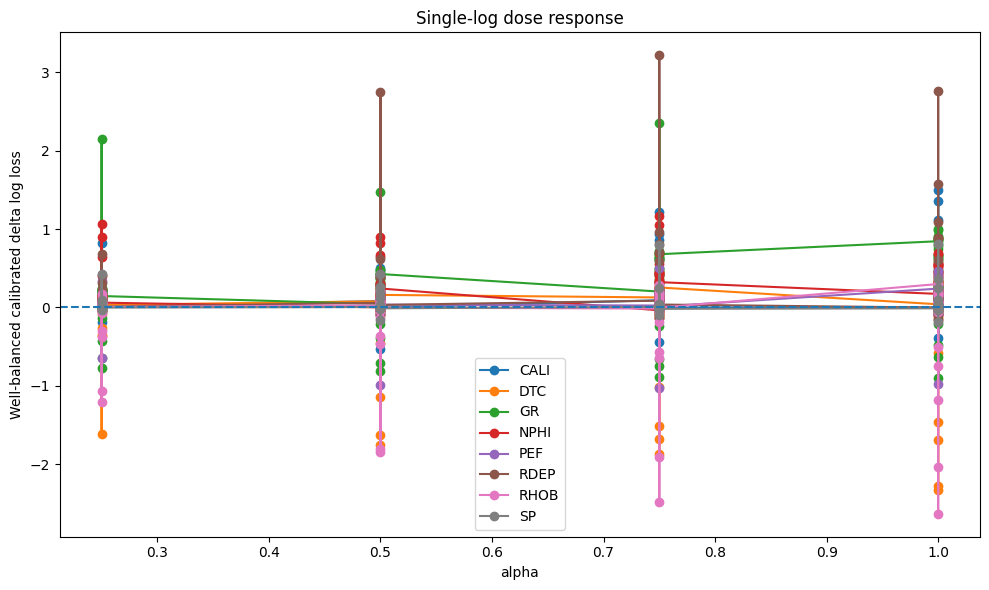

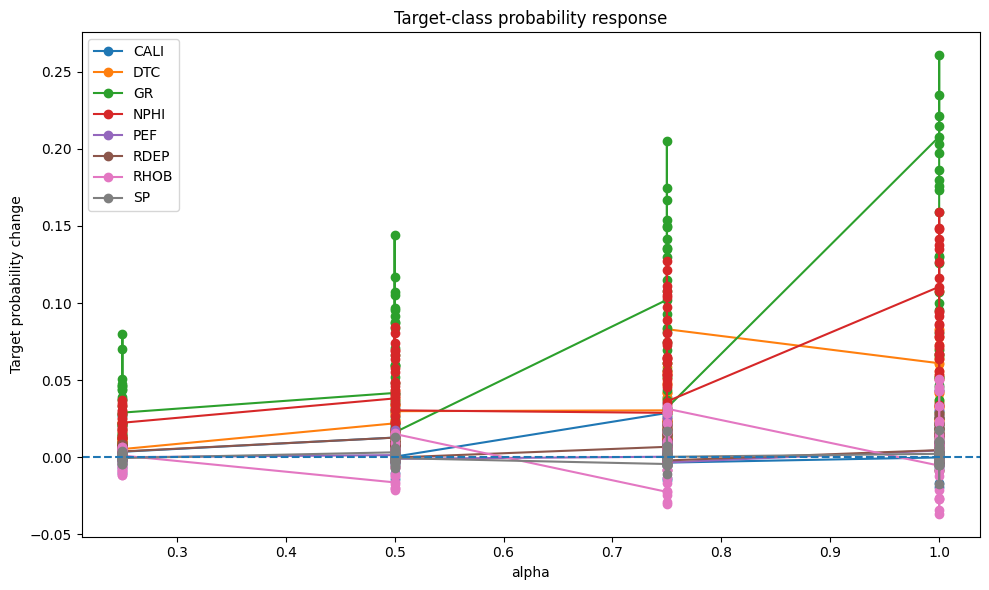

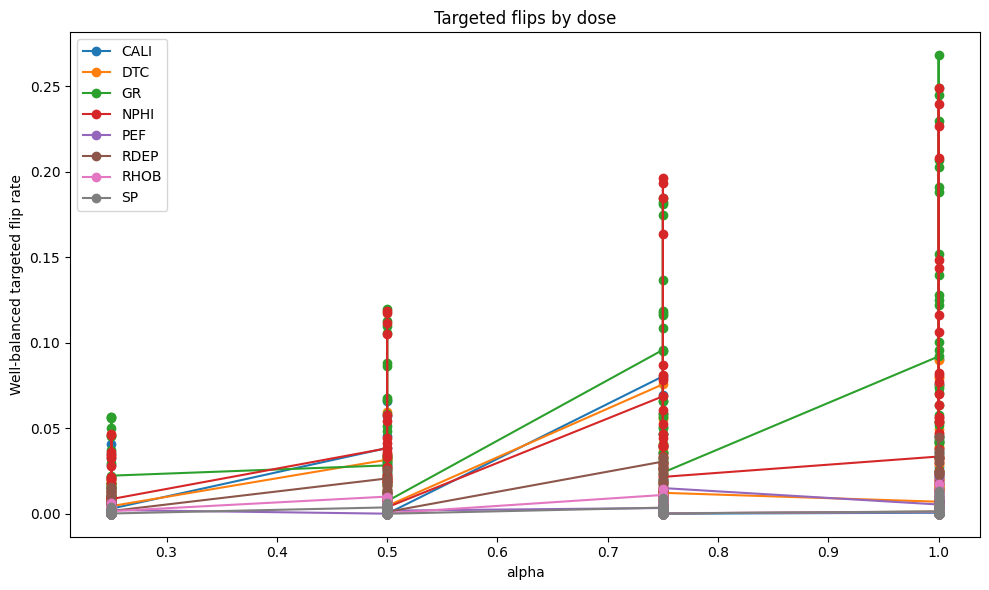

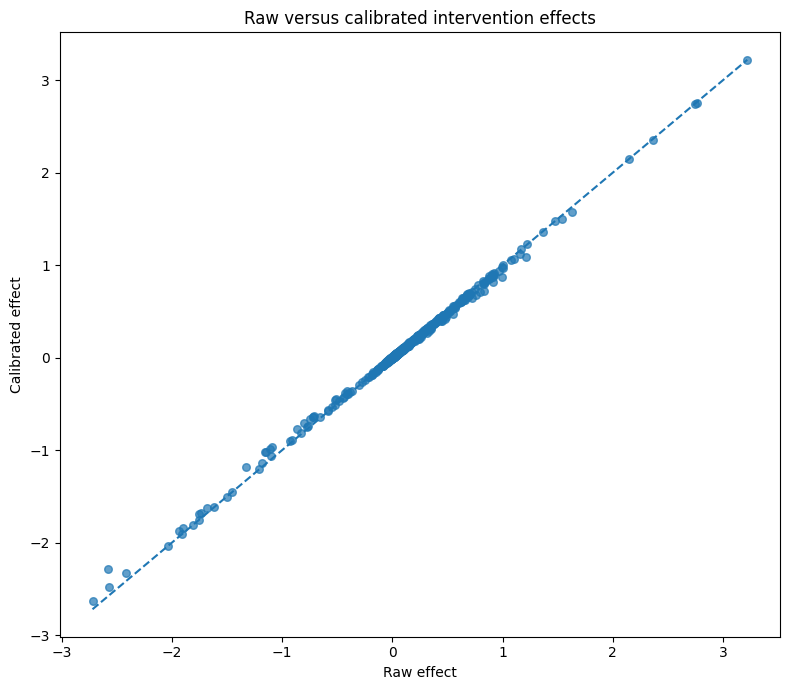

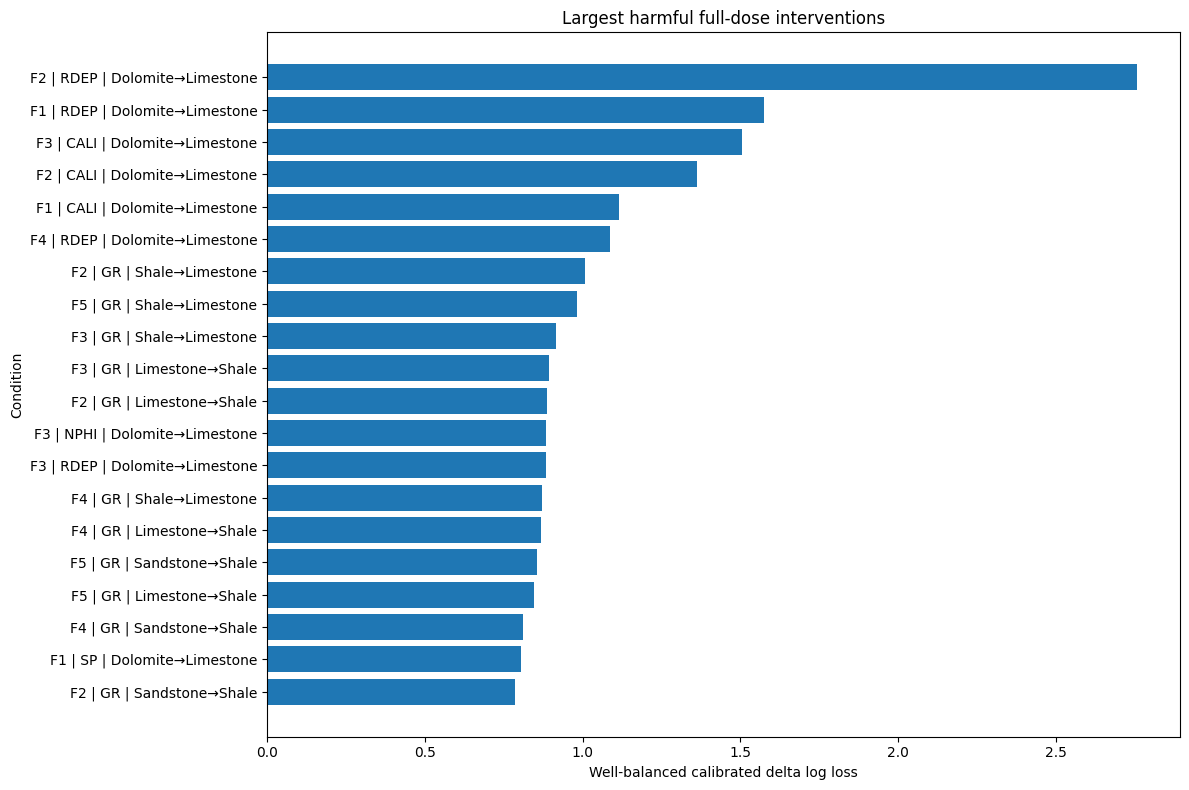

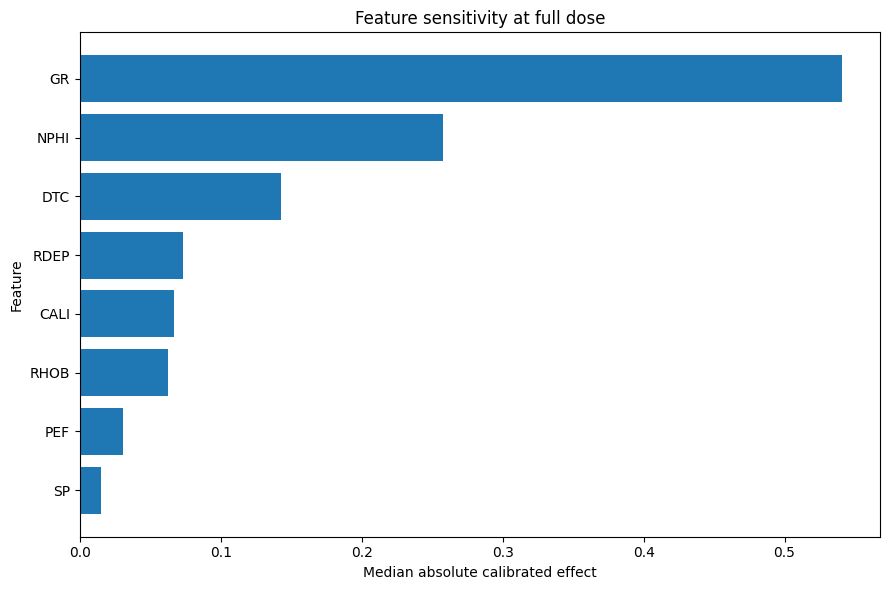

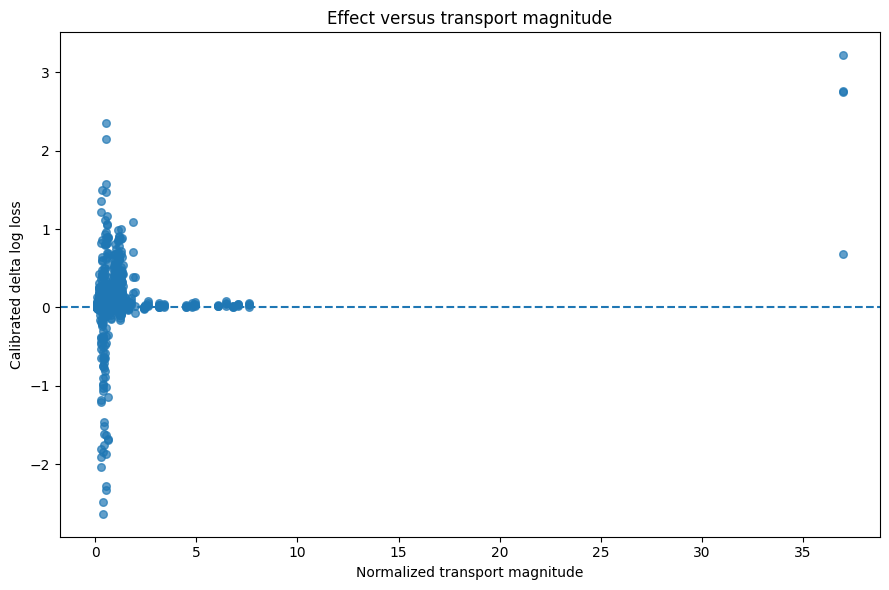

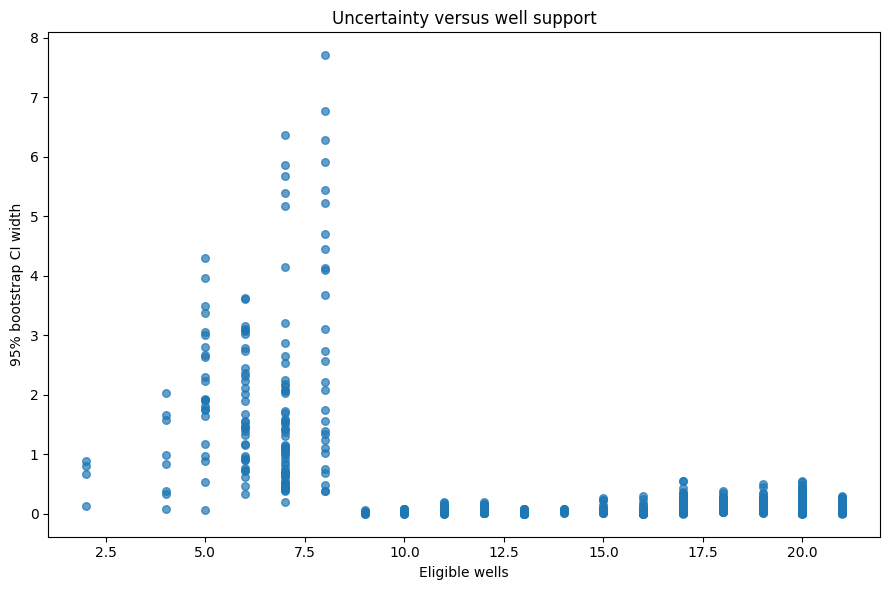

In [13]:
def savefig(name):
    plt.tight_layout(); plt.savefig(PLOT_DIR/name,dpi=220,bbox_inches="tight"); plt.show(); plt.close()

# Primary dose response
plt.figure(figsize=(10,6))
for feature,g in summary.groupby("feature"):
    g=g.sort_values("alpha"); plt.plot(g.alpha,g.well_balanced_mean_calibrated_delta_log_loss,marker="o",label=feature)
plt.axhline(0,linestyle="--"); plt.xlabel("alpha"); plt.ylabel("Well-balanced calibrated delta log loss"); plt.title("Single-log dose response"); plt.legend(); savefig("01_primary_dose_response.png")

plt.figure(figsize=(10,6))
for feature,g in summary.groupby("feature"):
    g=g.sort_values("alpha"); plt.plot(g.alpha,g.mean_calibrated_delta_target_probability,marker="o",label=feature)
plt.axhline(0,linestyle="--"); plt.xlabel("alpha"); plt.ylabel("Target probability change"); plt.title("Target-class probability response"); plt.legend(); savefig("02_target_probability_response.png")

plt.figure(figsize=(10,6))
for feature,g in summary.groupby("feature"):
    g=g.sort_values("alpha"); plt.plot(g.alpha,g.well_balanced_targeted_flip_rate,marker="o",label=feature)
plt.xlabel("alpha"); plt.ylabel("Well-balanced targeted flip rate"); plt.title("Targeted flips by dose"); plt.legend(); savefig("03_targeted_flip_response.png")

plt.figure(figsize=(8,7)); plt.scatter(summary.well_balanced_mean_raw_delta_log_loss,summary.well_balanced_mean_calibrated_delta_log_loss,s=30,alpha=.7)
lo=min(summary.well_balanced_mean_raw_delta_log_loss.min(),summary.well_balanced_mean_calibrated_delta_log_loss.min()); hi=max(summary.well_balanced_mean_raw_delta_log_loss.max(),summary.well_balanced_mean_calibrated_delta_log_loss.max()); plt.plot([lo,hi],[lo,hi],linestyle="--"); plt.xlabel("Raw effect"); plt.ylabel("Calibrated effect"); plt.title("Raw versus calibrated intervention effects"); savefig("04_raw_vs_calibrated_effects.png")

alpha1=summary.loc[np.isclose(summary.alpha,1)].sort_values("well_balanced_mean_calibrated_delta_log_loss",ascending=False).head(MAX_TOP_PLOTS).copy(); alpha1["label"]="F"+alpha1.outer_fold.astype(str)+" | "+alpha1.feature+" | "+alpha1.source_name+"→"+alpha1.target_name
plt.figure(figsize=(12,8)); plt.barh(alpha1.label[::-1],alpha1.well_balanced_mean_calibrated_delta_log_loss[::-1]); plt.xlabel("Well-balanced calibrated delta log loss"); plt.ylabel("Condition"); plt.title("Largest harmful full-dose interventions"); savefig("05_top_harmful_alpha1.png")

fr=feature_ranking.loc[np.isclose(feature_ranking.alpha,1)].sort_values("median_absolute_cal_effect")
plt.figure(figsize=(9,6)); plt.barh(fr.feature,fr.median_absolute_cal_effect); plt.xlabel("Median absolute calibrated effect"); plt.ylabel("Feature"); plt.title("Feature sensitivity at full dose"); savefig("06_feature_ranking_alpha1.png")

plt.figure(figsize=(9,6)); plt.scatter(summary.mean_normalized_transport_shift,summary.well_balanced_mean_calibrated_delta_log_loss,s=30,alpha=.7); plt.axhline(0,linestyle="--"); plt.xlabel("Normalized transport magnitude"); plt.ylabel("Calibrated delta log loss"); plt.title("Effect versus transport magnitude"); savefig("07_effect_vs_transport_magnitude.png")

summary["calibrated_CI_width"]=summary.calibrated_CI_upper-summary.calibrated_CI_lower
plt.figure(figsize=(9,6)); plt.scatter(summary.wells,summary.calibrated_CI_width,s=30,alpha=.7); plt.xlabel("Eligible wells"); plt.ylabel("95% bootstrap CI width"); plt.title("Uncertainty versus well support"); savefig("08_CI_width_vs_wells.png")

In [14]:
expected_conditions=len(selected); observed_conditions=condition_gates.condition_id.nunique(); expected_doses=expected_conditions*4
stage_gate={
 "official_test_unused":True,"04C_passed":bool(gate04["overall_transport_bank_passed"]),"05A_passed":bool(gate05a["overall_raw_feature_contract_passed"]),
 "05B_passed":bool(gate05b["overall_raw_RF_grouped_CV_passed"]),"05C_passed":bool(gate05c["overall_strict_nested_temperature_calibration_passed"]),
 "file12_used_for_controls":True,"frozen_models_used":True,"frozen_imputers_used":True,"frozen_temperatures_used":True,
 "no_model_or_imputer_refit":True,"outer_train_transport_mapping":True,"interventions_only_on_outer_validation":True,
 "single_log_at_a_time":True,"true_source_label_unchanged":True,"natural_missing_treatment_rows_excluded":True,
 "all_fold_replays_passed":bool(fold_replay_df.fold_replay_passed.all()),"expected_condition_count":expected_conditions,"observed_condition_count":observed_conditions,
 "condition_count_correct":observed_conditions==expected_conditions,"all_condition_gates_passed":bool(condition_gates.condition_gate_passed.all()),
 "expected_condition_dose_count":expected_doses,"observed_condition_dose_count":len(summary),"condition_dose_count_correct":len(summary)==expected_doses,
 "well_balanced_primary_estimand":True,"positive_delta_log_loss_means_harm":True,"raw_and_calibrated_effects_saved":True,"run_mode":RUN_MODE,
}
stage_gate["overall_raw_RF_transport_intervention_stage_passed"]=bool(all(v for k,v in stage_gate.items() if k not in ["expected_condition_count","observed_condition_count","expected_condition_dose_count","observed_condition_dose_count","run_mode","overall_raw_RF_transport_intervention_stage_passed"]))
print(json.dumps(stage_gate,indent=2))
if not stage_gate["overall_raw_RF_transport_intervention_stage_passed"]: raise RuntimeError("06A stage gate failed.")

cleaning_summary.to_csv(OUT/"00_cleaning_summary.csv",index=False)
selected.to_csv(OUT/"01_selected_intervention_conditions.csv",index=False)
fold_replay_df.to_csv(OUT/"02_frozen_model_control_replay_audit.csv",index=False)
execution.to_csv(OUT/"03_condition_execution_manifest.csv",index=False)
condition_gates.to_csv(OUT/"04_condition_gates.csv",index=False)
summary.to_csv(OUT/"05_condition_dose_effect_summary.csv",index=False)
per_well.to_parquet(OUT/"06_all_per_well_effects.parquet",index=False); per_well.to_csv(OUT/"06_all_per_well_effects.csv",index=False)
dose_response.to_csv(OUT/"07_dose_response_summary.csv",index=False)
asym.to_csv(OUT/"08_direction_asymmetry_summary.csv",index=False)
feature_ranking.to_csv(OUT/"09_feature_effect_ranking.csv",index=False)
transitions.to_parquet(OUT/"10_prediction_transition_summary.parquet",index=False); transitions.to_csv(OUT/"10_prediction_transition_summary.csv",index=False)
with open(OUT/"11_stage_gate.json","w",encoding="utf-8") as f: json.dump(json_safe(stage_gate),f,indent=2,ensure_ascii=False)
run_config={"stage":"06A_raw_RF_class_conditional_transport_interventions","run_mode":RUN_MODE,"official_test_used":False,"model_variant":"raw8","active_outer_folds":ACTIVE_FOLDS,"features":RAW8_FEATURES,"doses":DOSES,"selected_condition_count":len(selected),"control_probability_source":str(FILE12),"temperature_source":str(TEMP_MAP_PATH),"transport_bank_source":str(BANK_DIR),"primary_outcome":"delta log loss = intervention loss - control loss","primary_estimand":"mean within WELL then equal mean across WELLs","single_log_at_a_time":True,"true_label_unchanged":True,"save_row_level_results":SAVE_ROW_LEVEL_RESULTS,"bootstrap_replicates":BOOTSTRAP_REPLICATES,"BH_FDR_alpha":BH_ALPHA,"claim_scope":"retrospective class-conditional model vulnerability analysis","next_stage":"06B_legacy_RF_class_conditional_transport_interventions"}
with open(OUT/"12_run_configuration.json","w",encoding="utf-8") as f: json.dump(json_safe(run_config),f,indent=2,ensure_ascii=False)
hashes={"train":sha256_file(TRAIN_PATH),"fold_assignment":sha256_file(FOLD_PATH),"04C_manifest":sha256_file(MANIFEST04),"05C_file12":sha256_file(FILE12),"05C_temperature_map":sha256_file(TEMP_MAP_PATH)}
with open(OUT/"13_input_hashes.json","w",encoding="utf-8") as f: json.dump(hashes,f,indent=2)
env={"python":platform.python_version(),"platform":platform.platform(),"numpy":np.__version__,"pandas":pd.__version__,"scipy":scipy.__version__,"sklearn":sklearn.__version__,"joblib":joblib.__version__}
with open(OUT/"14_environment.json","w",encoding="utf-8") as f: json.dump(env,f,indent=2)
print("✅ 06A passed")
print("Outputs:",OUT)

{
  "official_test_unused": true,
  "04C_passed": true,
  "05A_passed": true,
  "05B_passed": true,
  "05C_passed": true,
  "file12_used_for_controls": true,
  "frozen_models_used": true,
  "frozen_imputers_used": true,
  "frozen_temperatures_used": true,
  "no_model_or_imputer_refit": true,
  "outer_train_transport_mapping": true,
  "interventions_only_on_outer_validation": true,
  "single_log_at_a_time": true,
  "true_source_label_unchanged": true,
  "natural_missing_treatment_rows_excluded": true,
  "all_fold_replays_passed": true,
  "expected_condition_count": 319,
  "observed_condition_count": 319,
  "condition_count_correct": true,
  "all_condition_gates_passed": true,
  "expected_condition_dose_count": 1276,
  "observed_condition_dose_count": 1276,
  "condition_dose_count_correct": true,
  "well_balanced_primary_estimand": true,
  "positive_delta_log_loss_means_harm": true,
  "raw_and_calibrated_effects_saved": true,
  "run_mode": "full",
  "overall_raw_RF_transport_intervention